# SAR · Sistema de Análisis de Reseñas
### De cientos de miles de reseñas a una decisión: qué categorías priorizar
**Proyecto final · Procesamiento de Lenguaje Natural · Luis Pedro González**

| | |
|---|---|
| **Usuario final** | Gerente de categorías / equipo de experiencia del cliente de una tienda en línea |
| **Decisión** | ¿A qué **3 categorías** les asigno primero el presupuesto de mejora este trimestre, y **qué problema** ataco en cada una? |
| **Por qué NLP** | El promedio de estrellas dice *cuánto* molesta algo, pero no *qué* molesta. La causa está escrita en el texto, y nadie puede leer millones de reseñas a mano. |
| **Producto** | Dashboard web: ranking de prioridad, causas, tendencia, reseñas de ejemplo y un clasificador de sentimiento en vivo. |

**Flujo end-to-end:** 1. Captura → 2. Exploración → 3. Limpieza y transformación → 4. Modelado (Naive Bayes vs. Regresión Logística) → 5. De modelo a decisión → 6. Modelo de valor → 7. Limitaciones → 8. Exportación al dashboard → 9. Viabilidad.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

pd.set_option("display.max_colwidth", 160)
SEMILLA = 42
DATOS = Path("datos")
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

# Paleta (la misma de la presentación)
NAVY, TEAL, NARANJA, GRIS = "#14213D", "#0F766E", "#E4572E", "#8A94A6"
COLOR_SENT = {"negativa": NARANJA, "neutra": GRIS, "positiva": TEAL}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})

# Nombres de categoría en español (los datos vienen en inglés)
CATEGORIA_ES = {
    "Electronics": "Electrónica", "Cell_Phones_and_Accessories": "Celulares y accesorios",
    "Home_and_Kitchen": "Hogar y cocina", "Toys_and_Games": "Juguetes y juegos",
    "Sports_and_Outdoors": "Deportes y aire libre", "Tools_and_Home_Improvement": "Herramientas y mejoras del hogar",
    "Beauty_and_Personal_Care": "Belleza y cuidado personal", "Automotive": "Automotriz",
    "Clothing_Shoes_and_Jewelry": "Ropa, zapatos y joyería", "Pet_Supplies": "Mascotas",
    "Patio_Lawn_and_Garden": "Patio y jardín", "Office_Products": "Oficina",
    "Baby_Products": "Bebés", "Video_Games": "Videojuegos", "Health_and_Household": "Salud y hogar",
}

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIGURAS / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

---
## 1. Captura de datos

### 1.1 Fuente: Amazon Reviews 2023 (McAuley Lab, UC San Diego)
- **Fuente:** [amazon-reviews-2023.github.io](https://amazon-reviews-2023.github.io/), 571 millones de reseñas reales de Amazon (EE. UU.), de 1996 a septiembre de 2023, con su **distribución natural** (sin balanceo artificial de estrellas). Ver `FUENTE_DE_DATOS.md`.
- **Idioma:** los datos están en inglés. Todo el análisis, las gráficas y el dashboard están en español.
- **Campos:** estrellas, título, texto, producto (`parent_asin`), usuario, fecha, votos de "útil" y si la compra fue verificada.

### 1.2 Cómo se capturaron
- **`01_captura_datos.py`:** cada categoría es un archivo de varios GB (unos 200 GB las 15 categorías), ordenado por cliente. Tomar las primeras filas daría una muestra de pocos clientes, así que el script lee **1,000 trozos en posiciones aleatorias** de cada archivo (solicitudes HTTP por rango de bytes) y toma **20,000 reseñas al azar por categoría**, solo de **2019 en adelante**, porque la decisión es sobre la situación actual.
- **15 categorías × 20,000 = 300,000 reseñas.**
- **`02_estimar_volumen.py`:** como la muestra tiene el mismo tamaño por categoría, el volumen real se estima con el total oficial de cada categoría × la proporción de sus reseñas que son de 2019 en adelante.
- **`01b_extracto_crudo.py`:** guarda un extracto de cada archivo original sin modificar (`datos_crudos/`).

In [2]:
df = pd.concat([pd.read_parquet(p) for p in sorted(DATOS.glob("*.parquet"))], ignore_index=True)
df["categoria"] = df["category"].map(CATEGORIA_ES)
df["fecha"] = pd.to_datetime(df["timestamp"], unit="ms")
df["rating"] = df["rating"].astype(int)
print(f"{len(df):,} reseñas · {df['category'].nunique()} categorías · "
      f"{df['parent_asin'].nunique():,} productos · {df['user_id'].nunique():,} usuarios")
print(f"Fechas: {df['fecha'].min():%Y-%m-%d} a {df['fecha'].max():%Y-%m-%d}")
df[["rating", "title", "text", "categoria", "fecha", "helpful_vote", "verified_purchase"]].head()

300,000 reseñas · 15 categorías · 211,927 productos · 239,139 usuarios
Fechas: 2019-01-01 a 2023-09-11


,rating,title,text,categoria,fecha,helpful_vote,verified_purchase
0,5,NICE,Like the dual sound....sound like a car now...not a toy!,Automotriz,2022-05-30 02:27:23.038,0,True
1,1,Does not fit in Norcold light bracket,the light modules are too long shoulder to shoulder to fit into the brackets on the Norcold fridge light. This is one of the specified compatible models (N...,Automotriz,2023-02-21 00:08:46.839,0,True
2,5,Thank you,Awesome item,Automotriz,2019-05-07 02:28:13.471,0,True
3,4,Ok,"I feel like it was a little expensive for what you actually get, but the quality is ok and seems to be protecting carpet for the most part",Automotriz,2023-03-31 15:50:59.234,0,True
4,5,"Tygon is the standard, right?","Motion Pro makes this simple, reordetable piece available. And that's a reliable, durable product from a reliable, durable supplier.",Automotriz,2022-09-07 11:46:11.594,0,True


In [3]:
volumen = pd.read_csv(DATOS / "volumen_categorias.csv")
volumen["categoria"] = volumen["category"].map(CATEGORIA_ES)
volumen.sort_values("resenas_2019_millones", ascending=False)

,category,total_oficial_millones,prop_2019,resenas_2019_millones,n_medidas,categoria
2,Home_and_Kitchen,67.4,0.659,44.42,10163,Hogar y cocina
8,Clothing_Shoes_and_Jewelry,66.0,0.633,41.79,11085,"Ropa, zapatos y joyería"
0,Electronics,43.9,0.493,21.63,9087,Electrónica
5,Tools_and_Home_Improvement,27.0,0.655,17.67,10350,Herramientas y mejoras del hogar
14,Health_and_Household,25.6,0.627,16.05,10700,Salud y hogar
6,Beauty_and_Personal_Care,23.9,0.615,14.70,9973,Belleza y cuidado personal
7,Automotive,20.0,0.597,11.94,10685,Automotriz
1,Cell_Phones_and_Accessories,20.8,0.563,11.71,10341,Celulares y accesorios
10,Patio_Lawn_and_Garden,16.5,0.683,11.26,9977,Patio y jardín
9,Pet_Supplies,16.8,0.630,10.59,9526,Mascotas


### 1.3 Distribución de estrellas

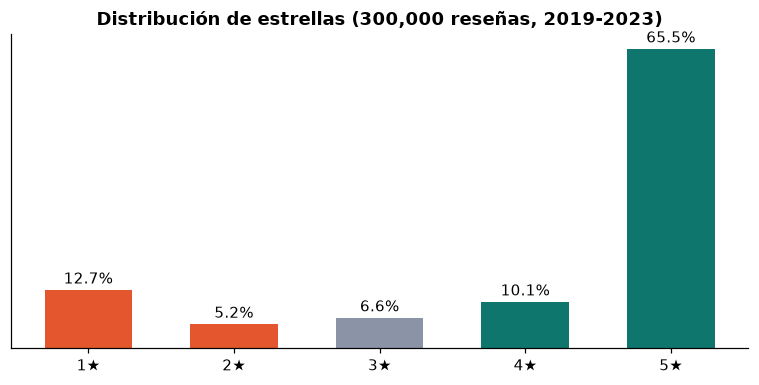

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
pct = df["rating"].value_counts(normalize=True).sort_index() * 100
barras = ax.bar([f"{i}★" for i in pct.index], pct.values, color=[NARANJA, NARANJA, GRIS, TEAL, TEAL], width=0.6)
ax.bar_label(barras, fmt="%.1f%%", padding=2)
ax.set_title("Distribución de estrellas (300,000 reseñas, 2019-2023)")
ax.set_yticks([])
guardar("01_distribucion_estrellas")

La distribución tiene la forma de **"J"** típica de las reseñas en línea: la mayoría da 5★, hay un pico de quejas en 1★ y muy pocas reseñas intermedias.

---
## 2. Análisis exploratorio

In [5]:
def sentimiento(r):
    return "negativa" if r <= 2 else ("neutra" if r == 3 else "positiva")

df["sentimiento"] = df["rating"].map(sentimiento)
df["palabras"] = df["text"].fillna("").str.split().str.len()

resumen = (df.groupby("categoria")
             .agg(resenas=("rating", "size"), estrellas_prom=("rating", "mean"),
                  pct_negativa=("sentimiento", lambda s: (s == "negativa").mean() * 100))
             .round(2).sort_values("pct_negativa", ascending=False))
print((df["sentimiento"].value_counts(normalize=True) * 100).round(1))
resumen

sentimiento
positiva    75.6
negativa    17.8
neutra       6.6
Name: proportion, dtype: float64


,resenas,estrellas_prom,pct_negativa
categoria,,,
Patio y jardín,20000,3.99,21.06
Videojuegos,20000,4.01,20.02
Celulares y accesorios,20000,4.03,19.96
Electrónica,20000,4.05,19.28
Mascotas,20000,4.05,19.28
Belleza y cuidado personal,20000,4.08,18.48
Herramientas y mejoras del hogar,20000,4.11,17.74
Salud y hogar,20000,4.12,17.67
Automotriz,20000,4.13,17.57


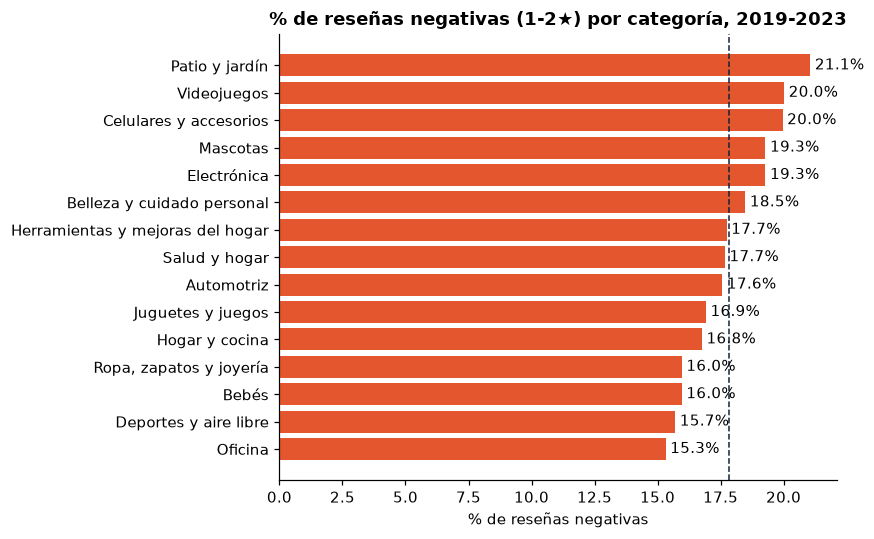

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
orden = resumen.sort_values("pct_negativa")
barras = ax.barh(orden.index, orden["pct_negativa"], color=NARANJA)
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.axvline(orden["pct_negativa"].mean(), color=NAVY, ls="--", lw=1)
ax.set_title("% de reseñas negativas (1-2★) por categoría, 2019-2023")
ax.set_xlabel("% de reseñas negativas")
guardar("02_pct_negativa_categoria")

**Lectura:** el 75.6 % de las reseñas es positiva, el 17.8 % negativa y solo el 6.6 % neutra. Entre categorías, el % negativo va de **15.3 % (Oficina) a 21.1 % (Patio y jardín)**. Las diferencias parecen pequeñas, pero con 20,000 reseñas por categoría el margen de error es de ±0.5 puntos, así que son diferencias reales.

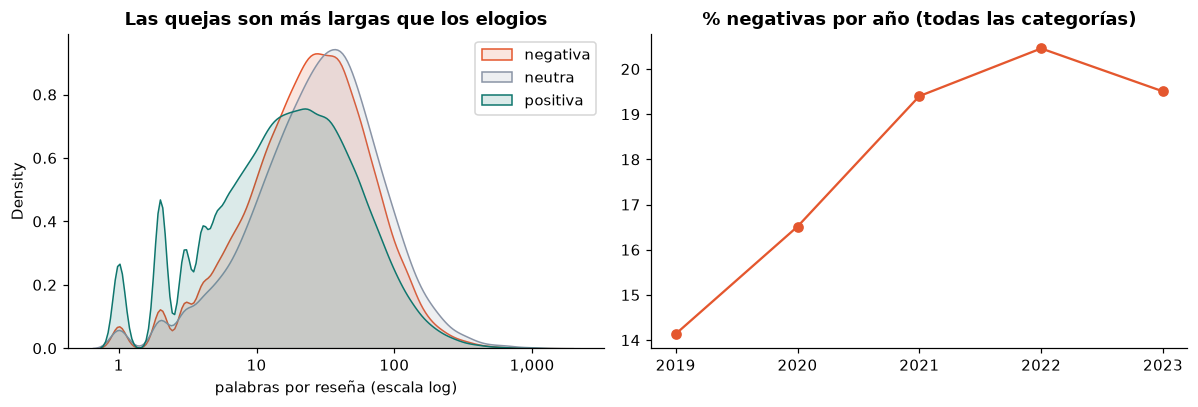

sentimiento
negativa    26.0
neutra      30.0
positiva    17.0
Name: mediana de palabras, dtype: float64
Compras verificadas: 93.9%
Reseñas con al menos 1 voto de 'útil': 19.2%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for s in ["negativa", "neutra", "positiva"]:
    sns.kdeplot(np.log10(df.loc[df["sentimiento"] == s, "palabras"].clip(lower=1)), ax=axes[0],
                label=s, color=COLOR_SENT[s], fill=True, alpha=0.15)
axes[0].set_xticks([0, 1, 2, 3], ["1", "10", "100", "1,000"])
axes[0].set_xlabel("palabras por reseña (escala log)")
axes[0].set_title("Las quejas son más largas que los elogios")
axes[0].legend()
por_anio = df.groupby(df["fecha"].dt.year)["sentimiento"].apply(lambda s: (s == "negativa").mean() * 100)
axes[1].plot(por_anio.index, por_anio.values, marker="o", color=NARANJA)
axes[1].set_title("% negativas por año (todas las categorías)")
axes[1].set_xticks(por_anio.index)
guardar("03_largo_y_anio")
print(df.groupby("sentimiento")["palabras"].median().rename("mediana de palabras"))
print(f"Compras verificadas: {df['verified_purchase'].mean():.1%}")
print(f"Reseñas con al menos 1 voto de 'útil': {(df['helpful_vote'] > 0).mean():.1%}")

**Lectura:** una reseña negativa típica tiene 26 palabras y una positiva 17: el cliente molesto explica *qué* falló, y por eso el texto sirve para encontrar causas. El % de reseñas negativas **subió cada año desde 2019**, así que el problema es creciente. El 93.9 % son compras verificadas.

---
## 3. Limpieza y transformación

Decisiones documentadas:

| Paso | Decisión | Por qué |
|---|---|---|
| 1 | Unir **título + texto** | El título resume la opinión ("Broke after 2 weeks") y aporta mucha señal. |
| 2 | Quitar etiquetas HTML (`<br />`), marcadores de video (`[[VIDEOID:…]]`), enlaces y números | Son ruido del formato de Amazon, no opinión. |
| 3 | Expandir negaciones: `don't` → `do not` | Para que "not" sobreviva como palabra. |
| 4 | Minúsculas y quitar signos | Normalización estándar. |
| 5 | Quitar stopwords **excepto negaciones e intensificadores** (`not`, `no`, `never`, `very`, `too`…) | "not good" y "good" significan lo contrario. |
| 6 | Eliminar textos vacíos y duplicados | Mismo usuario + mismo producto + mismo texto cuenta una sola vez. |
| 7 | Etiqueta: 1-2★ negativa · 3★ neutra · 4-5★ positiva | Convención habitual en reseñas de 5 estrellas: 3★ es una opinión intermedia. |
| 8 | TF-IDF con palabras y pares de palabras (bigramas) | Bigramas capturan "stopped working", "poor quality". |

In [8]:
print("Valores nulos por columna:\n", df[["rating", "title", "text", "category"]].isna().sum().to_dict())
print(f"Reseñas con etiquetas HTML: {df['text'].str.contains('<br', na=False).mean():.1%}")
print(f"Reseñas con enlaces: {df['text'].str.contains('http', na=False).mean():.2%}")
print(f"Reseñas con marcadores de video: {df['text'].str.contains('[[VIDEOID', regex=False, na=False).mean():.2%}")

NEGACION = re.compile(r"n['’]t\b")
HTML = re.compile(r"<[^>]+>")
VIDEO = re.compile(r"\[\[[^\]]*\]\]")
URL = re.compile(r"https?://\S+|www\.\S+")
NO_LETRAS = re.compile(r"[^a-z\s]")
ESPACIOS = re.compile(r"\s+")

def limpiar(texto):
    t = texto.lower()
    t = HTML.sub(" ", t)
    t = VIDEO.sub(" ", t)
    t = URL.sub(" ", t)
    t = t.replace("can't", "can not").replace("won't", "will not")
    t = NEGACION.sub(" not", t)
    t = NO_LETRAS.sub(" ", t)
    return ESPACIOS.sub(" ", t).strip()

df["texto_completo"] = df["title"].fillna("") + ". " + df["text"].fillna("")
# versión legible del texto original, para mostrar reseñas de ejemplo
df["text"] = df["text"].fillna("").str.replace(HTML, " ", regex=True).str.replace(VIDEO, " ", regex=True).str.strip()
df["texto_limpio"] = df["texto_completo"].map(limpiar)

antes = len(df)
df = df[df["texto_limpio"].str.split().str.len() >= 3]
vacias = antes - len(df)
df = df.drop_duplicates(subset=["user_id", "parent_asin", "texto_limpio"])
print(f"Eliminadas: {vacias:,} reseñas casi vacías y {antes - vacias - len(df):,} duplicadas → quedan {len(df):,}")

Valores nulos por columna:
 {'rating': 0, 'title': 0, 'text': 0, 'category': 0}
Reseñas con etiquetas HTML: 7.8%
Reseñas con enlaces: 0.03%
Reseñas con marcadores de video: 0.90%


Eliminadas: 4,550 reseñas casi vacías y 11 duplicadas → quedan 295,439


In [9]:
ejemplo = df[df["texto_completo"].str.contains("<br", regex=False) & df["texto_completo"].str.contains("n't", regex=False)
            & df["palabras"].between(25, 45)].iloc[0]
print("ANTES:\n", ejemplo["texto_completo"], "\n\nDESPUÉS:\n", ejemplo["texto_limpio"])

ANTES:
 keeping windshield  Clear. The magnets don't hold on and wind justs flaps away. Have trouble when I take it off hard to fold during<br />cold weather.<br />Summer hoping will keep the inside cooler. Fits well. 

DESPUÉS:
 keeping windshield clear the magnets do not hold on and wind justs flaps away have trouble when i take it off hard to fold during cold weather summer hoping will keep the inside cooler fits well


In [10]:
SE_QUEDAN = {"no", "not", "nor", "never", "none", "nothing", "cannot", "nobody", "neither", "very", "too",
             "but", "against", "off", "back", "again", "enough", "less", "few", "more", "most", "only", "well",
             "up", "down"}
STOPWORDS = sorted(ENGLISH_STOP_WORDS - SE_QUEDAN)
print(f"{len(STOPWORDS)} stopwords; se conservan: {sorted(SE_QUEDAN)}")

293 stopwords; se conservan: ['again', 'against', 'back', 'but', 'cannot', 'down', 'enough', 'few', 'less', 'more', 'most', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'off', 'only', 'too', 'up', 'very', 'well']


---
## 4. Modelado: Naive Bayes vs. Regresión Logística

**Para qué sirve el modelo en el producto:** las estrellas solo existen en las reseñas. Las quejas que llegan por correo, chat o redes sociales no traen estrellas. El clasificador permite medir el sentimiento de **cualquier texto** de un cliente y alimentar el mismo dashboard. En el dashboard se puede probar en vivo.

**Evaluación:** dividimos en entrenamiento / validación / prueba (70/15/15, estratificado). Elegimos hiperparámetros con validación y reportamos el resultado final **una sola vez** en prueba. Como las clases están desbalanceadas (pocas neutras), la métrica principal es **F1 macro**: un modelo que dice "positiva" siempre tendría buena accuracy y sería inútil.

In [11]:
X_temp, X_test, y_temp, y_test = train_test_split(df["texto_limpio"], df["sentimiento"], test_size=0.15,
                                                  stratify=df["sentimiento"], random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15 / 0.85,
                                                  stratify=y_temp, random_state=SEMILLA)
print(f"Entrenamiento {len(X_train):,} · Validación {len(X_val):,} · Prueba {len(X_test):,}")

tfidf = TfidfVectorizer(stop_words=STOPWORDS, ngram_range=(1, 2), min_df=5, max_df=0.5,
                        max_features=50_000, sublinear_tf=True)
Xtr = tfidf.fit_transform(X_train)
Xva = tfidf.transform(X_val)
Xte = tfidf.transform(X_test)
print(f"Matriz TF-IDF de entrenamiento: {Xtr.shape[0]:,} reseñas × {Xtr.shape[1]:,} términos")

Entrenamiento 206,807 · Validación 44,316 · Prueba 44,316


Matriz TF-IDF de entrenamiento: 206,807 reseñas × 50,000 términos


In [12]:
resultados = []
base = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)
resultados.append(("Línea base (siempre 'positiva')", "-", base))

for alpha in [0.1, 0.3, 1.0]:
    nb = MultinomialNB(alpha=alpha).fit(Xtr, y_train)
    resultados.append(("Naive Bayes", f"alpha={alpha}", nb))

for C in [0.25, 0.5, 1, 2]:
    lr = LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEMILLA).fit(Xtr, y_train)
    resultados.append(("Regresión Logística", f"C={C}", lr))

tabla_val = pd.DataFrame([{
    "modelo": n, "parámetro": p,
    "accuracy": accuracy_score(y_val, m.predict(Xva)),
    "F1 macro": f1_score(y_val, m.predict(Xva), average="macro"),
    "F1 negativa": f1_score(y_val, m.predict(Xva), labels=["negativa"], average="macro"),
} for n, p, m in resultados]).round(3)
tabla_val

,modelo,parámetro,accuracy,F1 macro,F1 negativa
0,Línea base (siempre 'positiva'),-,0.753,0.286,0.000
1,Naive Bayes,alpha=0.1,0.883,0.629,0.789
2,Naive Bayes,alpha=0.3,0.882,0.614,0.789
3,Naive Bayes,alpha=1.0,0.878,0.576,0.779
4,Regresión Logística,C=0.25,0.840,0.692,0.783
5,Regresión Logística,C=0.5,0.847,0.693,0.783
6,Regresión Logística,C=1,0.852,0.694,0.782
7,Regresión Logística,C=2,0.855,0.690,0.780


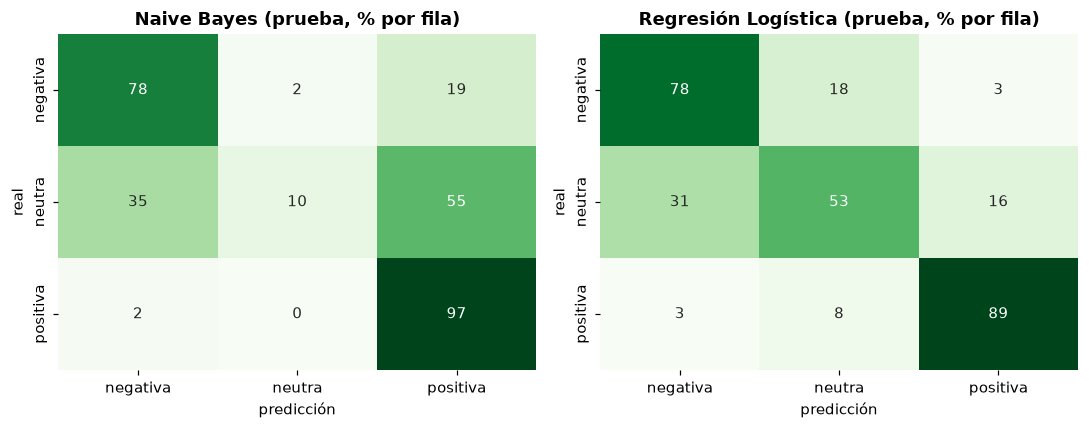

,modelo,accuracy,F1 macro,F1 negativa,F1 neutra,F1 positiva
0,Naive Bayes,0.882,0.632,0.783,0.170,0.942
1,Regresión Logística,0.850,0.691,0.776,0.364,0.933


In [13]:
mejor_nb = max((r for r in resultados if r[0] == "Naive Bayes"),
               key=lambda r: f1_score(y_val, r[2].predict(Xva), average="macro"))[2]
mejor_lr = max((r for r in resultados if r[0] == "Regresión Logística"),
               key=lambda r: f1_score(y_val, r[2].predict(Xva), average="macro"))[2]
CLASES = ["negativa", "neutra", "positiva"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
tabla_test = []
for ax, (nombre, modelo) in zip(axes, [("Naive Bayes", mejor_nb), ("Regresión Logística", mejor_lr)]):
    pred = modelo.predict(Xte)
    tabla_test.append({"modelo": nombre, "accuracy": accuracy_score(y_test, pred),
                       "F1 macro": f1_score(y_test, pred, average="macro"),
                       **{f"F1 {c}": f1_score(y_test, pred, labels=[c], average="macro") for c in CLASES}})
    cm = confusion_matrix(y_test, pred, labels=CLASES, normalize="true") * 100
    sns.heatmap(cm, annot=True, fmt=".0f", cmap="Greens", cbar=False, ax=ax,
                xticklabels=CLASES, yticklabels=CLASES)
    ax.set_title(f"{nombre} (prueba, % por fila)")
    ax.set_xlabel("predicción")
    ax.set_ylabel("real")
guardar("04_matrices_confusion")
tabla_test = pd.DataFrame(tabla_test).round(3)
tabla_test

In [14]:
print("Regresión Logística — reporte completo en prueba\n")
print(classification_report(y_test, mejor_lr.predict(Xte), digits=3))

Regresión Logística — reporte completo en prueba

              precision    recall  f1-score   support

    negativa      0.770     0.783     0.776      8002
      neutra      0.277     0.531     0.364      2942
    positiva      0.977     0.894     0.933     33372

    accuracy                          0.850     44316
   macro avg      0.674     0.736     0.691     44316
weighted avg      0.893     0.850     0.867     44316



**Lectura de los resultados:**
- La **línea base** (decir siempre "positiva") acierta el 75 % pero tiene F1 macro de 0.29 y no detecta ninguna queja. Por eso la accuracy sola engaña con clases desbalanceadas.
- **Naive Bayes** tiene la accuracy más alta (0.88), pero casi nunca predice "neutra" (F1 neutra = 0.17).
- **La Regresión Logística gana en F1 macro (0.69 vs. 0.63)** porque, con `class_weight="balanced"`, aprende a reconocer las tres clases. Para el negocio importa la clase **negativa**: detecta el 78 % de las quejas (recall) y el 77 % de lo que marca como queja realmente lo es (precisión).
- La clase **neutra** es la más difícil (F1 = 0.36). Una reseña de 3★ suele mezclar elogios y quejas ("funciona bien, pero…"), y hasta para una persona es ambigua.

**Modelo elegido: Regresión Logística**. Es el que mejor equilibra las tres clases y es interpretable.

### 4.1 Interpretación: qué palabras empujan hacia "negativa"
La regresión logística aprende un peso por término: es interpretable, y esos pesos son la primera pista de las causas.

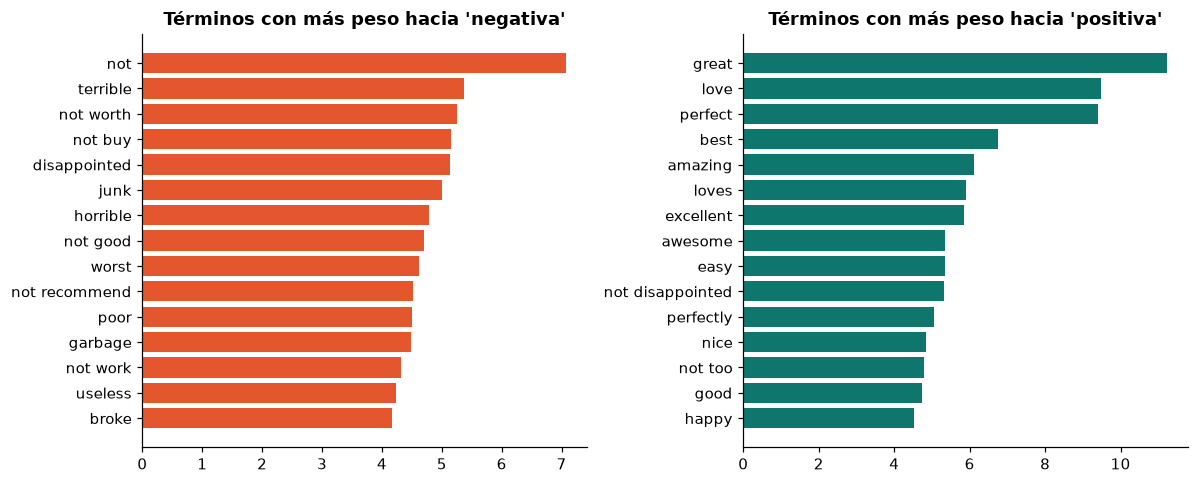

In [15]:
vocab = np.array(tfidf.get_feature_names_out())
pesos = pd.DataFrame(mejor_lr.coef_.T, index=vocab, columns=mejor_lr.classes_)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, clase, color in [(axes[0], "negativa", NARANJA), (axes[1], "positiva", TEAL)]:
    top = pesos[clase].sort_values().tail(15)
    ax.barh(top.index, top.values, color=color)
    ax.set_title(f"Términos con más peso hacia '{clase}'")
guardar("05_pesos_regresion_logistica")

Los pesos tienen sentido lingüístico: "terrible", "not worth", "not buy", "disappointed", "junk" y "broke" empujan hacia negativa, y "great", "love", "perfect" hacia positiva. Hacia neutra empujan "but", "okay", "mediocre" y "average": justo el lenguaje de una opinión mixta.

**La decisión de conservar las negaciones (paso 5) se confirma:** "disappointed" empuja hacia negativa, pero el bigrama **"not disappointed" es uno de los términos más positivos**. Sin "not" en el vocabulario, el modelo leería esa reseña al revés.

### 4.2 Análisis de errores

In [16]:
prueba = pd.DataFrame({"texto": df.loc[X_test.index, "texto_completo"], "estrellas": df.loc[X_test.index, "rating"],
                       "real": y_test, "predicción": mejor_lr.predict(Xte)})
errores = prueba[prueba["real"] != prueba["predicción"]]
print(f"Errores: {len(errores):,} de {len(prueba):,} ({len(errores) / len(prueba):.1%})")
print((pd.crosstab(errores["real"], errores["predicción"], normalize="all") * 100).round(1))
errores[errores["texto"].str.len() < 220].sample(8, random_state=SEMILLA)

Errores: 6,668 de 44,316 (15.0%)
predicción  negativa  neutra  positiva
real                                  
negativa         0.0    22.2       3.9
neutra          13.8     0.0       6.9
positiva        14.3    39.0       0.0


,texto,estrellas,real,predicción
237853,"Stop looking, this is your bar.. Really holds up to use. No issues whatsoever. It is not in a doorway that is of concern to paint scuffs, but I haven't noti...",5,positiva,negativa
97925,Very nice...but not for me. Very pretty comfortable blousy top...just didn't look great on me ...im short and a little petite...so it looked like it swallow...,5,positiva,neutra
250795,Battery door is very difficult to remove to change the battery. Bathroom decoration,3,neutra,negativa
186692,"Good price. Ordered this to hang a bird bath. Even with the longest setting, this still felt short. Will be using it for hanging planters.",5,positiva,neutra
83645,"Wrong colors. Right undies wrong color, I specifically selected them for the color, green is our little guys favorite color. We got an assorted colors pack....",5,positiva,negativa
10069,it reads codes on nissan 2016 and 2017. it reads engine codes on 2016 Nissan nvp350 not on Transmation<br />it also Works on 2017 Titan xd diesel engine and...,4,positiva,negativa
195011,The chime is weak.. The chime music is weak,2,negativa,neutra
66319,"It’s good. It’s a great case , it just doesn’t take much to make it bulky and not being able to close. But it gets the job done , especially for someone lik...",4,positiva,neutra


**Análisis de errores:** el 82 % de los errores involucra a la clase **neutra**. Los errores graves (confundir negativa con positiva) son solo el 18 % de los errores, el 2.7 % de todas las reseñas. Los casos difíciles son reseñas mixtas ("buen precio, pero…"), quejas sobre algo ajeno al producto ("pedí el color equivocado") y reseñas donde las estrellas no coinciden con el texto.

### 4.3 ¿El modelo aporta valor, o cualquiera podría adivinarlo?
Comparamos el modelo contra lo que haría una persona sin modelo: una **regla de sentido común** que cuenta palabras obviamente negativas (*bad, broke, terrible, waste, disappointed…*) y positivas (*great, love, perfect…*) y decide según cuáles son más.

In [17]:
PALABRAS_NEG = r"\b(not|bad|broke|broken|poor|terrible|horrible|awful|worst|waste|disappointed|disappointing|junk|garbage|useless|return|returned|refund|cheap|defective)\b"
PALABRAS_POS = r"\b(great|love|perfect|excellent|amazing|awesome|best|good|nice|happy)\b"

def regla_sentido_comun(texto):
    neg, pos = len(re.findall(PALABRAS_NEG, texto)), len(re.findall(PALABRAS_POS, texto))
    return "negativa" if neg > pos else ("positiva" if pos > neg else "neutra")

pred_regla = X_test.map(regla_sentido_comun)
pred_lr = mejor_lr.predict(Xte)
comparacion = pd.DataFrame([{
    "método": nombre, "accuracy": accuracy_score(y_test, pred),
    "F1 macro": f1_score(y_test, pred, average="macro"),
    "F1 negativa": f1_score(y_test, pred, labels=["negativa"], average="macro"),
} for nombre, pred in [("Regla de sentido común", pred_regla), ("Regresión Logística", pred_lr)]]).round(3)
comparacion

,método,accuracy,F1 macro,F1 negativa
0,Regla de sentido común,0.625,0.503,0.632
1,Regresión Logística,0.850,0.691,0.776


**El modelo le gana claramente a la regla:** acierta el 85 % contra el 62.5 %, y en quejas tiene F1 de 0.78 contra 0.63. La regla falla porque no entiende el contexto: "not bad" tiene "not" y "bad", y la regla lo cuenta como queja doble.

**¿Hacían falta más datos?** Entrenamos el mismo modelo con porciones cada vez más grandes del conjunto de entrenamiento:

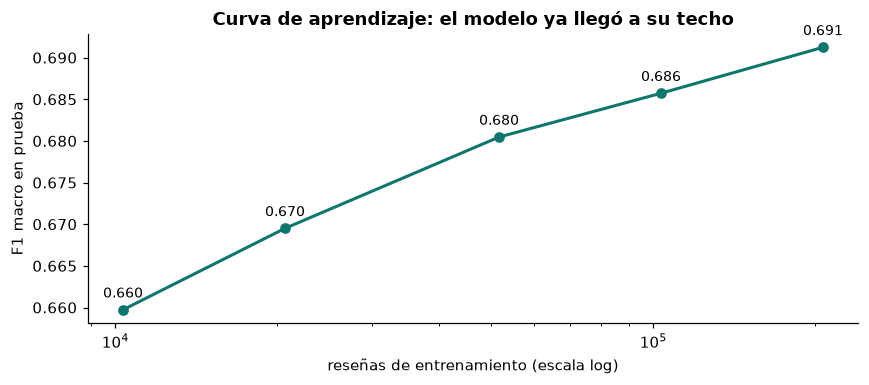

,reseñas de entrenamiento,F1 macro
0,10340,0.660
1,20680,0.670
2,51701,0.680
3,103403,0.686
4,206807,0.691


In [18]:
curva = []
for fraccion in [0.05, 0.1, 0.25, 0.5, 1.0]:
    n = int(Xtr.shape[0] * fraccion)
    m = LogisticRegression(C=mejor_lr.C, class_weight="balanced", max_iter=2000, random_state=SEMILLA)
    m.fit(Xtr[:n], y_train.iloc[:n])
    curva.append({"reseñas de entrenamiento": n, "F1 macro": f1_score(y_test, m.predict(Xte), average="macro")})
curva = pd.DataFrame(curva)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva["reseñas de entrenamiento"], curva["F1 macro"], marker="o", color=TEAL, lw=2)
for _, r in curva.iterrows():
    ax.annotate(f"{r['F1 macro']:.3f}", (r["reseñas de entrenamiento"], r["F1 macro"]),
                xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("reseñas de entrenamiento (escala log)")
ax.set_ylabel("F1 macro en prueba")
ax.set_title("Curva de aprendizaje: el modelo ya llegó a su techo")
guardar("09_curva_aprendizaje")
curva.round(3)

**Lectura:** al pasar de 100 mil a 200 mil reseñas, el F1 solo sube 0.005. El modelo ya llegó a su techo con estos datos, así que bajar millones de reseñas más no lo mejoraría de forma importante. Para mejorar habría que cambiar de técnica (por ejemplo, un modelo preentrenado como BERT), no agregar datos.

---
## 5. De modelo a decisión

### 5.1 ¿Dónde está el problema? Porcentaje **y** volumen
- **% negativa** (de la muestra): qué tan grave es el problema dentro de la categoría.
- **Volumen real 2019+** (estimado): cuántas reseñas tiene realmente la categoría.
- **Reseñas negativas estimadas = volumen × % negativa**: cuántos clientes insatisfechos dejaron constancia. Este es el criterio de prioridad.

In [19]:
prioridad = (df.groupby("categoria")
               .agg(resenas_muestra=("sentimiento", "size"),
                    pct_negativa=("sentimiento", lambda s: (s == "negativa").mean() * 100))
               .join(volumen.set_index("categoria")[["resenas_2019_millones"]]))
# margen de error al 95 % del % negativo de cada categoría
p = prioridad["pct_negativa"] / 100
prioridad["margen_error"] = 1.96 * np.sqrt(p * (1 - p) / prioridad["resenas_muestra"]) * 100
prioridad["negativas_estimadas_millones"] = prioridad["resenas_2019_millones"] * p
prioridad = prioridad.sort_values("negativas_estimadas_millones", ascending=False)
prioridad["rank_volumen"] = range(1, len(prioridad) + 1)
prioridad["rank_porcentaje"] = prioridad["pct_negativa"].rank(ascending=False).astype(int)
prioridad.round(2)

,resenas_muestra,pct_negativa,resenas_2019_millones,margen_error,negativas_estimadas_millones,rank_volumen,rank_porcentaje
categoria,,,,,,,
Hogar y cocina,19703,16.93,44.42,0.52,7.52,1,11
"Ropa, zapatos y joyería",19670,16.15,41.79,0.51,6.75,2,12
Electrónica,19710,19.51,21.63,0.55,4.22,3,4
Herramientas y mejoras del hogar,19683,17.95,17.67,0.54,3.17,4,7
Salud y hogar,19709,17.89,16.05,0.54,2.87,5,8
Belleza y cuidado personal,19731,18.66,14.70,0.54,2.74,6,6
Patio y jardín,19762,21.22,11.26,0.57,2.39,7,1
Celulares y accesorios,19627,20.26,11.71,0.56,2.37,8,3
Automotriz,19595,17.84,11.94,0.54,2.13,9,9


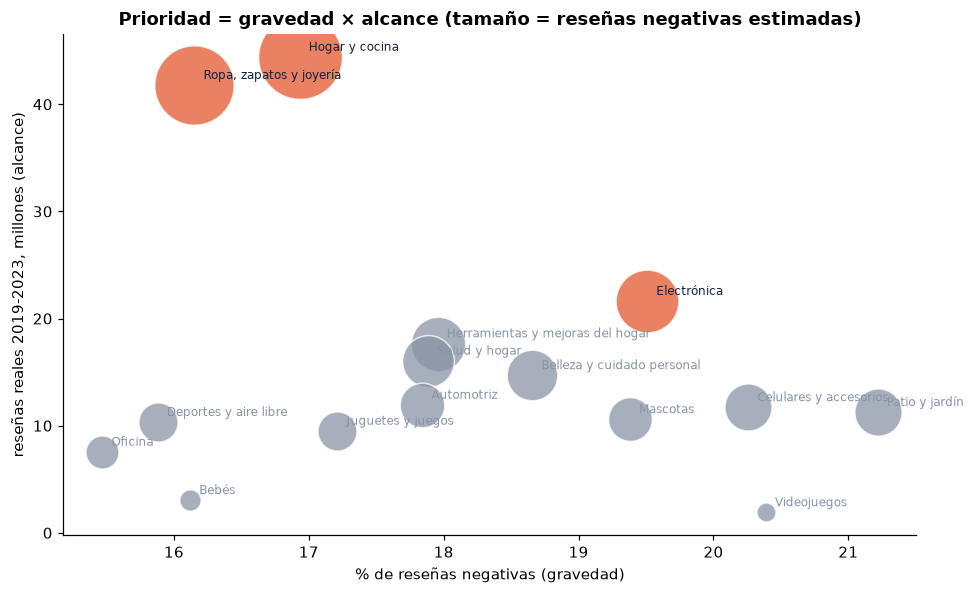

In [20]:
fig, ax = plt.subplots(figsize=(9, 5.5))
top3 = prioridad.index[:3]
for cat, fila in prioridad.iterrows():
    color = NARANJA if cat in top3 else GRIS
    ax.scatter(fila["pct_negativa"], fila["resenas_2019_millones"], s=fila["negativas_estimadas_millones"] * 400,
               color=color, alpha=0.75, edgecolor="white")
    ax.annotate(cat, (fila["pct_negativa"], fila["resenas_2019_millones"]), fontsize=8,
                xytext=(6, 4), textcoords="offset points", color=NAVY if cat in top3 else GRIS)
ax.set_xlabel("% de reseñas negativas (gravedad)")
ax.set_ylabel("reseñas reales 2019-2023, millones (alcance)")
ax.set_title("Prioridad = gravedad × alcance (tamaño = reseñas negativas estimadas)")
guardar("06_matriz_prioridad")

**Hallazgo clave: el porcentaje solo no alcanza.** Si se priorizara por % de reseñas negativas, se elegirían **Patio y jardín (21.2 %), Videojuegos (20.4 %) y Celulares (20.3 %)**. Pero **Hogar y cocina está en el puesto 11 por porcentaje y es la primera en clientes insatisfechos**: 7.5 millones de reseñas negativas estimadas, **19 veces más que Videojuegos** (0.39 millones). Combinar gravedad (%) y alcance (volumen) cambia por completo la decisión.

### 5.2 ¿Por qué? Causas de las quejas
Dos enfoques complementarios:
1. **Temas** definidos con un diccionario de expresiones (transparente y fácil de explicar al usuario de negocio).
2. **Frases distintivas** por categoría con TF-IDF por clase: cada categoría se trata como un "documento" con todas sus quejas, y TF-IDF resalta lo que es propio de esa categoría frente a las demás.

Reseñas negativas con al menos un tema: 63.5%


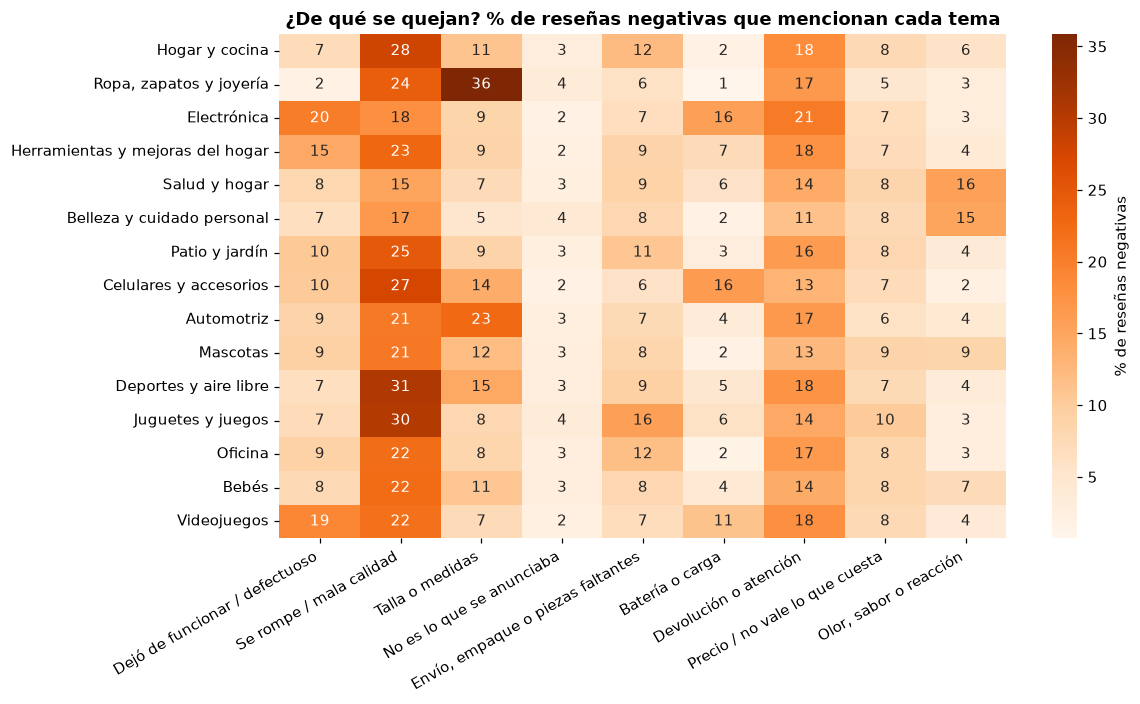

,causa principal,% de sus quejas
categoria,,
Hogar y cocina,Se rompe / mala calidad,28.0
"Ropa, zapatos y joyería",Talla o medidas,35.9
Electrónica,Dejó de funcionar / defectuoso,20.3
Herramientas y mejoras del hogar,Se rompe / mala calidad,22.9
Salud y hogar,"Olor, sabor o reacción",15.6
Belleza y cuidado personal,Se rompe / mala calidad,16.7
Patio y jardín,Se rompe / mala calidad,24.8
Celulares y accesorios,Se rompe / mala calidad,27.4
Automotriz,Talla o medidas,22.6


In [21]:
TEMAS = {
    "Dejó de funcionar / defectuoso": r"stopped working|stop working|quit working|not work|doesn ?t work|didn ?t work|"
                                      r"defective|dead on arrival|won ?t turn on|not turn on|malfunction|no longer works|died",
    "Se rompe / mala calidad": r"broke|broken|break|cheap|flimsy|poor quality|bad quality|low quality|fell apart|"
                               r"cracked|snapped|ripped|tore|torn|falling apart",
    "Talla o medidas": r"too small|too big|too large|too tight|too short|too long|runs small|runs large|"
                       r"\bfit\b|\bfits\b|size|sizing",
    "No es lo que se anunciaba": r"not as described|not as pictured|misleading|false advertising|fake|counterfeit|"
                                 r"knock ?off|not the same|different (?:than|from)|not what i (?:ordered|expected)",
    "Envío, empaque o piezas faltantes": r"arrived|shipping|shipped|package|packaging|delivered|delivery|"
                                         r"never received|missing|damaged",
    "Batería o carga": r"battery|batteries|charge|charging|charger",
    "Devolución o atención": r"refund|return|returned|customer service|seller|warranty|replacement",
    "Precio / no vale lo que cuesta": r"waste of money|not worth|overpriced|too expensive|money back",
    "Olor, sabor o reacción": r"smell|smells|odor|taste|rash|allergic|irritat|burn",
}
negativas = df[df["sentimiento"] == "negativa"].copy()
texto_neg = negativas["texto_completo"].str.lower()
for tema, patron in TEMAS.items():
    negativas[tema] = texto_neg.str.contains(patron, regex=True)
print(f"Reseñas negativas con al menos un tema: {negativas[list(TEMAS)].any(axis=1).mean():.1%}")

temas_cat = (negativas.groupby("categoria")[list(TEMAS)].mean() * 100).loc[prioridad.index]
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(temas_cat, annot=True, fmt=".0f", cmap="Oranges", cbar_kws={"label": "% de reseñas negativas"}, ax=ax)
ax.set_title("¿De qué se quejan? % de reseñas negativas que mencionan cada tema")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_ylabel("")
guardar("07_temas_por_categoria")

# "Devolución o atención" es una consecuencia (el cliente devuelve porque algo falló), no una causa:
# para decidir qué problema atacar usamos solo los temas de causa
CAUSAS = [t for t in TEMAS if t != "Devolución o atención"]
causa_principal = temas_cat[CAUSAS].idxmax(axis=1)
pd.DataFrame({"causa principal": causa_principal,
              "% de sus quejas": temas_cat[CAUSAS].max(axis=1).round(1)})

**Lectura:** cada categoría tiene un problema distinto. En **Hogar y cocina** domina que el producto **se rompe o es de mala calidad** (28 % de las quejas). En **Ropa** el problema es la **talla** (36 %). En **Electrónica**, que el producto **deja de funcionar** (20 %) y la **batería o carga** (16 %). El tema "Devolución o atención" aparece en todas porque es la consecuencia de los demás problemas.

Las frases distintivas dicen **en qué productos** se concentran las quejas: sábanas, freidoras de aire y cafeteras en Hogar; "size not true" y "order size up" en Ropa; accesorios de MacBook, discos duros y tarjetas SD en Electrónica.

In [22]:
docs_cat = negativas.groupby("categoria")["texto_limpio"].apply(" ".join)
ctfidf = TfidfVectorizer(stop_words=STOPWORDS, ngram_range=(2, 3), min_df=2, sublinear_tf=True)
M = ctfidf.fit_transform(docs_cat)
terminos = np.array(ctfidf.get_feature_names_out())
# descartamos frases que empiezan o terminan en conector ("controller but"), que no se leen como causa
legible = np.array([not (t.split()[0] in {"but", "not"} or t.split()[-1] in {"but", "not", "no", "very", "too", "did", "does", "do", "lb"})
                    for t in terminos])
frases_cat = {}
for i, cat in enumerate(docs_cat.index):
    puntaje = M[i].toarray().ravel() * legible
    frases_cat[cat] = list(terminos[puntaje.argsort()[::-1][:8]])
pd.DataFrame({cat: frases_cat[cat] for cat in prioridad.index[:6]})

,Hogar y cocina,"Ropa, zapatos y joyería",Electrónica,Herramientas y mejoras del hogar,Salud y hogar,Belleza y cuidado personal
0,king size,plus size,macbook pro,shower head,heating pad,makes hair
1,fitted sheet,normally wear,sound quality,light bulbs,pain relief,hair hair
2,air fryer,arch support,apple pencil,motion sensor,essential oil,dry hair
3,coffee pot,wear size,screen protector,string lights,car key,face wash
4,bed frame,order size up,hard drive,garage door,mop head,work hair
5,mattress topper,size not true,macbook air,smart home,taste terrible,hair color
6,drink cold,ordered size,audio quality,bought lights,too sweet,human hair
7,shower curtain,order size,sd card,solar lights,arch support,hair really


### 5.3 ¿Cómo cambia a lo largo de los años?
La muestra se tomó al azar de todo el periodo 2019-2023, así que cada año aparece en la proporción que tuvo en la realidad y se puede analizar por separado. Para cada categoría y año calculamos:
- **% de reseñas negativas** del año.
- **Reseñas negativas estimadas del año** = volumen real 2019-2023 × proporción de la muestra que cae en ese año × % negativo del año.

2023 solo llega a septiembre (el dataset termina ahí), así que sus volúmenes son de 9 meses.

**¿Hay suficientes datos por año?** Antes de separar, revisamos cuántas reseñas quedan en cada combinación de categoría y año, y qué margen de error tiene su % de reseñas negativas:

In [23]:
tamanos_anio = (df.assign(anio=df["fecha"].dt.year, negativa=df["sentimiento"] == "negativa")
                  .groupby(["categoria", "anio"]).agg(resenas=("negativa", "size"), quejas=("negativa", "sum"),
                                                      p=("negativa", "mean")))
tamanos_anio["margen ±pts"] = 1.96 * np.sqrt(tamanos_anio["p"] * (1 - tamanos_anio["p"]) / tamanos_anio["resenas"]) * 100
(tamanos_anio.groupby("anio")[["resenas", "quejas", "margen ±pts"]]
             .agg(["min", "median", "max"]).round(1)
             .rename(index={2023: "2023 (ene-sep)"}))

resenas               quejas              margen ±pts         \
                   min  median   max    min median   max         min median   
anio                                                                          
2019              3246  4178.0  4904    451  557.0   825         0.9    1.1   
2020              4245  4748.0  5224    627  801.0  1018         1.0    1.1   
2021              4414  4773.0  5372    809  942.0  1142         1.0    1.1   
2022              3616  4335.0  5083    642  881.0  1208         1.1    1.2   
2023 (ene-sep)    1552  1722.0  2233    283  336.0   432         1.6    1.8   

                     
                max  
anio                 
2019            1.3  
2020            1.2  
2021            1.2  
2022            1.4  
2023 (ene-sep)  2.1

**Lectura:** cada categoría tiene entre 3,200 y 5,400 reseñas por año (entre 1,550 y 2,250 en 2023, que tiene 9 meses), con al menos 450 quejas por año (280 en 2023). El margen de error del % de reseñas negativas por año es de **±1.1 puntos** en promedio (±1.8 en 2023). Es suficiente para comparar años y categorías: las diferencias que importan (por ejemplo, de 13 % a 19 % en Hogar y cocina) son mucho más grandes que el margen. **No** alcanzaría para análisis más finos, como los temas de las quejas por trimestre dentro de una sola categoría; para eso habría que descargar más reseñas por año.

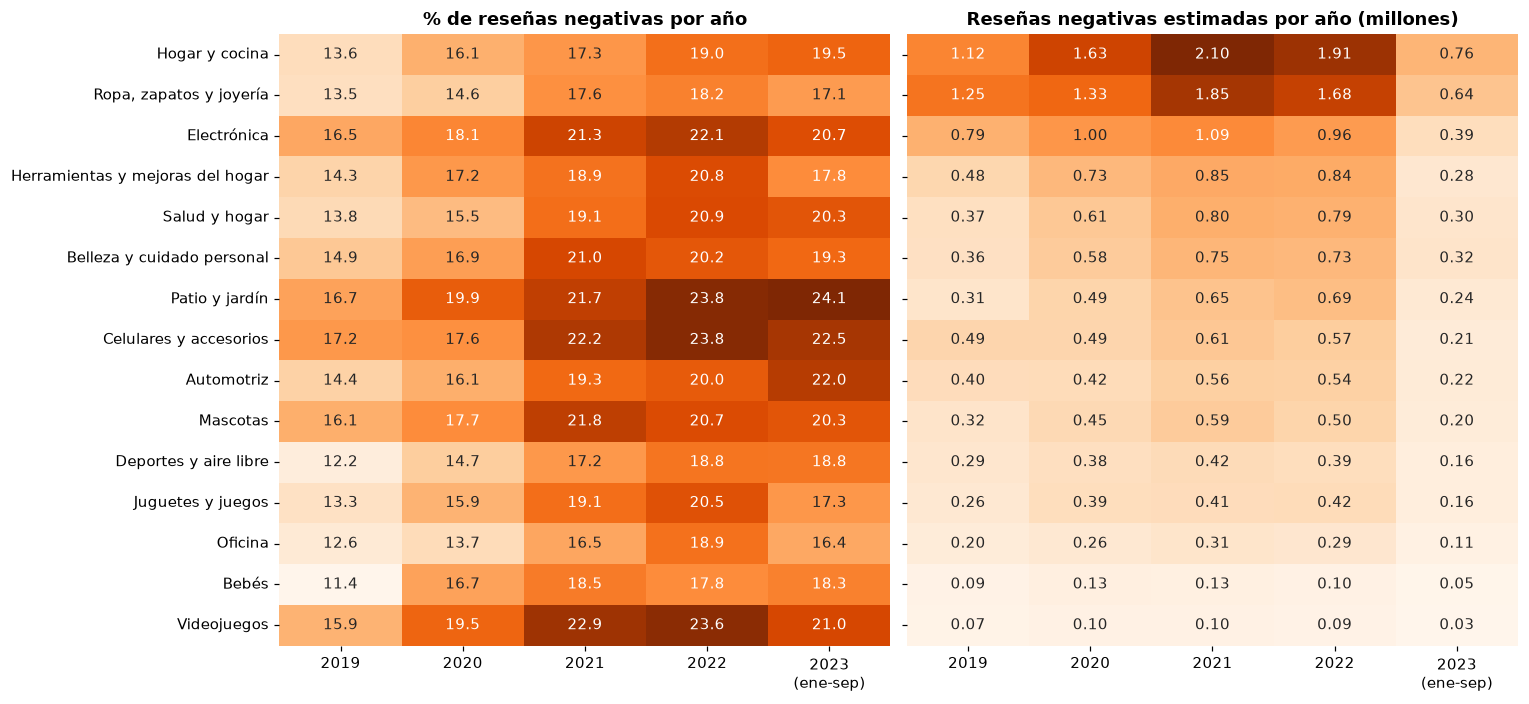

,2019,2020,2021,2022,2023
1.°,"Ropa, zapatos y joyería",Hogar y cocina,Hogar y cocina,Hogar y cocina,Hogar y cocina
2.°,Hogar y cocina,"Ropa, zapatos y joyería","Ropa, zapatos y joyería","Ropa, zapatos y joyería","Ropa, zapatos y joyería"
3.°,Electrónica,Electrónica,Electrónica,Electrónica,Electrónica


In [24]:
por_anio = (df.assign(anio=df["fecha"].dt.year, negativa=df["sentimiento"] == "negativa")
              .groupby(["categoria", "anio"]).agg(n=("negativa", "size"), pct=("negativa", "mean")).reset_index())
por_anio["proporcion"] = por_anio["n"] / por_anio.groupby("categoria")["n"].transform("sum")
por_anio["negativas_m"] = (por_anio["categoria"].map(prioridad["resenas_2019_millones"])
                           * por_anio["proporcion"] * por_anio["pct"])
por_anio["pct"] *= 100
pct_anio = por_anio.pivot(index="categoria", columns="anio", values="pct").loc[prioridad.index]
neg_anio = por_anio.pivot(index="categoria", columns="anio", values="negativas_m").loc[prioridad.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
sns.heatmap(pct_anio, annot=True, fmt=".1f", cmap="Oranges", cbar=False, ax=axes[0])
axes[0].set_title("% de reseñas negativas por año")
sns.heatmap(neg_anio, annot=True, fmt=".2f", cmap="Oranges", cbar=False, ax=axes[1])
axes[1].set_title("Reseñas negativas estimadas por año (millones)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels([*map(str, range(2019, 2023)), "2023\n(ene-sep)"])
guardar("10_resultados_por_anio")

top3_por_anio = pd.DataFrame({anio: list(neg_anio[anio].sort_values(ascending=False).index[:3])
                              for anio in neg_anio.columns}, index=["1.°", "2.°", "3.°"])
top3_por_anio

**Lectura:**
- **Todas las categorías empeoraron.** El % de reseñas negativas subió en las 15 entre 2019 y 2022: en el total pasó de 14.1 % a 20.5 %.
- **La decisión es estable en el tiempo:** Hogar y cocina, Ropa y Electrónica son las 3 prioridades **en los 5 años**. Solo en 2019 Ropa estaba primero y Hogar segundo. La recomendación no depende de un año particular.
- El volumen de quejas creció hasta 2021 y se mantuvo alto en 2022. 2023 se ve menor solo porque tiene 9 meses.

La siguiente gráfica muestra el detalle por trimestre:

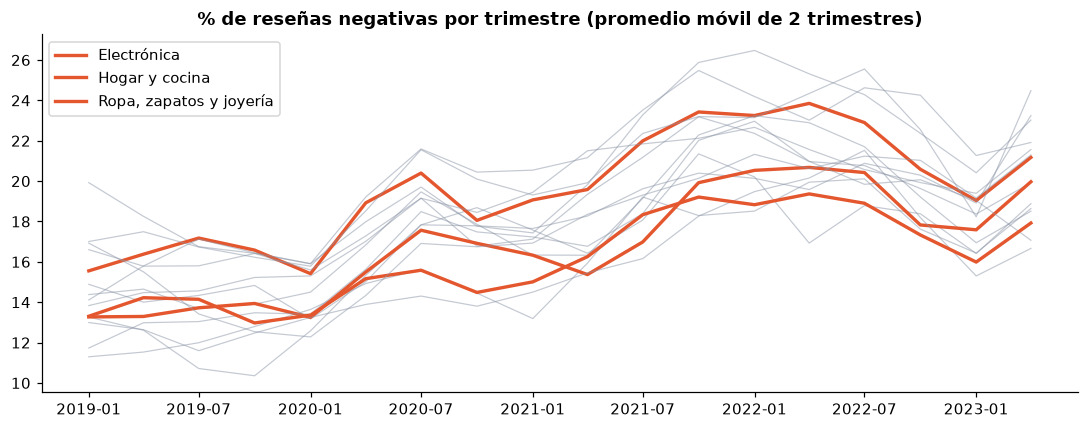

In [25]:
trimestral = (df.assign(trimestre=df["fecha"].dt.to_period("Q"))
                .groupby(["categoria", "trimestre"])["sentimiento"]
                .agg(lambda s: (s == "negativa").mean() * 100).unstack(0))
trimestral = trimestral[trimestral.index < pd.Period("2023Q3")]  # el último trimestre está incompleto
fig, ax = plt.subplots(figsize=(10, 4))
for cat in trimestral.columns:
    destacada = cat in top3
    ax.plot(trimestral.index.to_timestamp(), trimestral[cat].rolling(2, min_periods=1).mean(),
            color=NARANJA if destacada else GRIS, lw=2.2 if destacada else 0.8, alpha=1 if destacada else 0.5,
            label=cat if destacada else None)
ax.set_title("% de reseñas negativas por trimestre (promedio móvil de 2 trimestres)")
ax.legend()
guardar("08_tendencia_trimestral")

**Lectura:** las tres categorías prioritarias empeoraron entre **4 y 5.3 puntos** desde 2019, con un pico en 2022. El problema no es estable: está creciendo, y eso refuerza la urgencia de actuar este trimestre.

### 5.4 Evidencia: reseñas reales de clientes
Reseñas negativas sobre la causa principal de cada categoría, ordenadas por votos de "útil" (otros clientes confirmaron que les pasó lo mismo).

In [26]:
def evidencia(cat, n=3):
    # primero las reseñas cuyo título ya nombra el problema, luego por votos de "útil"
    patron = TEMAS[causa_principal[cat]]
    candidatas = negativas[(negativas["categoria"] == cat) & negativas[causa_principal[cat]]
                           & negativas["text"].str.len().between(100, 450)].copy()
    candidatas["titulo_lo_nombra"] = candidatas["title"].str.lower().str.contains(patron, regex=True)
    return candidatas.sort_values(["titulo_lo_nombra", "helpful_vote"], ascending=False).head(n)

for cat in top3:
    print(f"\n=== {cat} · causa principal: {causa_principal[cat]} ===")
    ej = evidencia(cat)
    for _, r in ej.iterrows():
        print(f"[{r['rating']}★ · {r['helpful_vote']} votos útiles] {r['title']} — {r['text'][:300]}")


=== Hogar y cocina · causa principal: Se rompe / mala calidad ===
[1★ · 16 votos útiles] Flimsy, they snap! Cheaply made — These are tempting to purchase because of the price, but don’t give in!!! Still not worth it!!! They are so cheap, thin, and flimsy. They break so easily. I have never had velvet hangers break like these do before.
[1★ · 14 votos útiles] Poor Quality — My significant other ordered a set of these for the living room and she has never been so frustrated building furniture. The parts are poor quality, the set screws are cheap, threads torn, if you drill them in they bust through the awful particle board. They give you a pack of white stickers to use 
[1★ · 9 votos útiles] Sent us a used broken toaster — When I unpacked it, I noticed the lever in the front for adjusting the level was broken off. Then I noticed that the side of the toaster was dirty. I pulled out the crumb tray and there was actually crumbs!  Clearly not new! Disgusting.  We have a similar model in whi

### 5.5 Recomendación: dónde invertir este trimestre

| Prioridad | Categoría | Clientes insatisfechos (reseñas negativas 2019-2023) | Problema a atacar | Acción sugerida |
|---|---|---|---|---|
| **1** | Hogar y cocina | **7.5 millones** (16.9 %) | Se rompe / mala calidad (28 % de las quejas) | Auditar a los proveedores con más quejas de calidad en ropa de cama y pequeños electrodomésticos (sábanas, freidoras de aire, cafeteras). |
| **2** | Ropa, zapatos y joyería | **6.8 millones** (16.2 %) | Talla o medidas (36 % de las quejas) | Guías de talla por marca y un aviso de "esta marca talla pequeño" calculado a partir de las reseñas. Menos devoluciones. |
| **3** | Electrónica | **4.2 millones** (19.5 %) | Deja de funcionar (20 %) y batería o carga (16 %) | Control de calidad y garantía visible en accesorios de computadora y almacenamiento (discos, tarjetas SD, accesorios de MacBook). |

**Respuesta a la pregunta de negocio:** invertir primero en **Hogar y cocina, Ropa y Electrónica**. Juntas concentran **18.5 millones** de reseñas negativas, el **45 %** de todas las quejas de las 15 categorías. Las tres empeoraron desde 2019 y son las 3 prioridades en cada uno de los 5 años.

### 5.6 Validación: ¿el modelo llegaría a la misma decisión sin estrellas?
El ranking de arriba usa las estrellas. Pero los correos, chats y comentarios en redes **no traen estrellas**. Para comprobar que el producto sirve en ese caso, tapamos las estrellas del conjunto de prueba (44,316 reseñas que el modelo nunca vio) y calculamos el ranking solo con lo que el modelo lee en el texto. Hacemos lo mismo con la regla de sentido común.

In [27]:
from scipy.stats import spearmanr

sin_estrellas = pd.DataFrame({
    "categoria": df.loc[X_test.index, "categoria"],
    "real (estrellas)": y_test == "negativa",
    "modelo (solo texto)": pred_lr == "negativa",
    "regla (solo texto)": pred_regla.values == "negativa",
}).groupby("categoria").mean() * 100
negativas_sin_estrellas = sin_estrellas.mul(prioridad["resenas_2019_millones"], axis=0) / 100
negativas_sin_estrellas = negativas_sin_estrellas.sort_values("real (estrellas)", ascending=False)

for col in negativas_sin_estrellas.columns:
    print(f"{col:22s} top 3: {list(negativas_sin_estrellas[col].sort_values(ascending=False).index[:3])}")
for col in ["modelo (solo texto)", "regla (solo texto)"]:
    rho = spearmanr(sin_estrellas["real (estrellas)"], sin_estrellas[col])[0]
    error = (negativas_sin_estrellas[col] / negativas_sin_estrellas["real (estrellas)"] - 1).abs().mean() * 100
    print(f"{col}: correlación del % por categoría con el real = {rho:.2f} · error promedio en millones de quejas = {error:.0f} %")
negativas_sin_estrellas.round(2).rename(columns=lambda c: f"quejas estimadas (M) · {c}")

real (estrellas)       top 3: ['Hogar y cocina', 'Ropa, zapatos y joyería', 'Electrónica']
modelo (solo texto)    top 3: ['Hogar y cocina', 'Ropa, zapatos y joyería', 'Electrónica']
regla (solo texto)     top 3: ['Hogar y cocina', 'Ropa, zapatos y joyería', 'Electrónica']
modelo (solo texto): correlación del % por categoría con el real = 0.95 · error promedio en millones de quejas = 4 %
regla (solo texto): correlación del % por categoría con el real = 0.90 · error promedio en millones de quejas = 45 %


,quejas estimadas (M) · real (estrellas),quejas estimadas (M) · modelo (solo texto),quejas estimadas (M) · regla (solo texto)
categoria,,,
Hogar y cocina,7.91,8.07,11.02
"Ropa, zapatos y joyería",6.58,5.98,8.78
Electrónica,4.41,4.67,6.23
Herramientas y mejoras del hogar,3.01,3.18,4.70
Salud y hogar,2.99,3.14,4.54
Belleza y cuidado personal,2.59,2.54,3.79
Celulares y accesorios,2.41,2.45,3.35
Patio y jardín,2.34,2.43,3.26
Automotriz,2.12,2.22,3.02


**Lectura:**
- Solo con el texto, el modelo llega a **las mismas 3 prioridades** y su % de quejas por categoría coincide casi exactamente con el real.
- La regla de sentido común también acierta el top 3 (lo define sobre todo el volumen enorme de esas categorías), pero **infla las cifras**: dice que hay muchas más quejas de las que hay. Con la regla, el presupuesto se decidiría con números equivocados.
- **Conclusión:** el modelo permite aplicar este mismo análisis a cualquier canal de texto de la empresa, aunque no tenga estrellas, con un error pequeño.

---
## 6. Modelo de valor: de métricas técnicas a dinero

**Escenario de uso.** La tienda recibe mensajes de clientes que no traen estrellas (correos, chats, comentarios). SAR clasifica cada mensaje y, si lo marca como **queja**, dispara una **acción de recuperación**: un agente contacta al cliente y le ofrece un cupón. La pregunta es: **¿a partir de qué probabilidad de queja conviene actuar?**

**Función de valor** (por mensaje, comparado con no hacer nada):

| Resultado | Qué pasa | Valor |
|---|---|---|
| Verdadero positivo (era queja y se actuó) | Se recupera al cliente con cierta probabilidad | **B − C** |
| Falso positivo (no era queja y se actuó) | Se gasta el cupón y el tiempo del agente en un cliente que ya estaba contento | **− C** |
| Falso negativo (era queja y no se actuó) | Se pierde la oportunidad (igual que sin el sistema) | 0 |
| Verdadero negativo | Nada | 0 |

**Valor = VP × B − (VP + FP) × C**, donde **B = tasa de recuperación × gasto anual × margen** y **C = cupón + minutos del agente × salario por hora**.

**Supuestos y fuentes:**

| Supuesto | Valor base | Fuente / justificación |
|---|---|---|
| Gasto anual de un cliente | US$ 570 | CIRP (2024): un cliente sin Prime gasta US$ 570 al año en Amazon (con Prime, US$ 1,170). Usamos el menor: es conservador. |
| Margen sobre ese gasto | 25 % | Supuesto conservador de margen bruto de comercio electrónico. Se prueba en la sensibilidad. |
| Tasa de recuperación (puntos adicionales de clientes que vuelven a comprar gracias al contacto) | 20 % | Kotler (*Marketing Management*): entre 54 % y 70 % de los clientes que se quejan vuelven a comprar si se resuelve su queja. Suponemos que sin contacto volvería una parte menor, y tomamos una diferencia de 20 puntos. |
| Cupón de compensación | US$ 10 | Supuesto: gesto de disculpa típico de bajo costo. |
| Tiempo del agente por contacto | 10 minutos | Supuesto: leer el caso, contactar y registrar. |
| Salario del agente | US$ 20.59 / hora | BLS (mayo 2024): mediana de *customer service representatives* en EE. UU. |

Con estos valores, **B = 0.20 × 570 × 0.25 = US$ 28.50** y **C = 10 + 10/60 × 20.59 = US$ 13.43**. Actuar solo conviene si la probabilidad de que el mensaje sea una queja supera **C / B ≈ 47 %**. Las cifras se expresan por cada **10,000 mensajes** y se evalúan en el conjunto de prueba (44,316 reseñas que el modelo no vio).

In [28]:
SUPUESTOS = {"gasto_anual": 570.0, "margen": 0.25, "recuperacion": 0.20,
             "cupon": 10.0, "minutos_agente": 10.0, "salario_hora": 20.59}
NOMBRE_SUPUESTO = {"gasto_anual": "Gasto anual del cliente", "margen": "Margen", "recuperacion": "Tasa de recuperación",
                   "cupon": "Cupón", "minutos_agente": "Minutos del agente", "salario_hora": "Salario del agente"}
MENSAJES = 10_000

def beneficio_y_costo(s):
    return s["recuperacion"] * s["gasto_anual"] * s["margen"], s["cupon"] + s["minutos_agente"] / 60 * s["salario_hora"]

es_queja = (y_test == "negativa").to_numpy()

def valor(marcadas, s=SUPUESTOS):
    b, c = beneficio_y_costo(s)
    vp = (marcadas & es_queja).sum()
    fp = (marcadas & ~es_queja).sum()
    return (vp * b - (vp + fp) * c) / len(marcadas) * MENSAJES

p_queja = {
    "Regresión Logística": mejor_lr.predict_proba(Xte)[:, list(mejor_lr.classes_).index("negativa")],
    "Naive Bayes": mejor_nb.predict_proba(Xte)[:, list(mejor_nb.classes_).index("negativa")],
}
UMBRALES = np.round(np.arange(0.02, 0.99, 0.01), 2)
curvas = pd.DataFrame({m: [valor(p >= u) for u in UMBRALES] for m, p in p_queja.items()}, index=UMBRALES)
f1_lr = pd.Series([f1_score(es_queja, p_queja["Regresión Logística"] >= u) for u in UMBRALES], index=UMBRALES)

u_opt = curvas["Regresión Logística"].idxmax()
u_opt_nb = curvas["Naive Bayes"].idxmax()
u_f1 = f1_lr.idxmax()
b, c = beneficio_y_costo(SUPUESTOS)
print(f"B = US$ {b:.2f} por queja recuperada · C = US$ {c:.2f} por acción · umbral de equilibrio C/B = {c / b:.0%}")
print(f"Umbral que maximiza el valor (Regresión Logística): {u_opt:.2f} · umbral que maximiza el F1: {u_f1:.2f}")

def resumen(nombre, marcadas):
    return {"estrategia": nombre, "mensajes marcados": int(marcadas.sum() / len(marcadas) * MENSAJES),
            "precisión": (marcadas & es_queja).sum() / max(marcadas.sum(), 1),
            "recall": (marcadas & es_queja).sum() / es_queja.sum(),
            "valor por 10,000 mensajes (US$)": valor(marcadas)}

p_lr = p_queja["Regresión Logística"]
estrategias = pd.DataFrame([
    resumen("No hacer nada", np.zeros_like(es_queja)),
    resumen("Contactar a todos", np.ones_like(es_queja)),
    resumen("Regla de sentido común", (pred_regla == "negativa").to_numpy()),
    resumen(f"Naive Bayes, umbral óptimo ({u_opt_nb:.2f})", p_queja["Naive Bayes"] >= u_opt_nb),
    resumen("Regresión Logística, clase más probable", pred_lr == "negativa"),
    resumen(f"Regresión Logística, umbral por F1 ({u_f1:.2f})", p_lr >= u_f1),
    resumen(f"Regresión Logística, umbral por valor ({u_opt:.2f})", p_lr >= u_opt),
])
estrategias.round(3)

B = US$ 28.50 por queja recuperada · C = US$ 13.43 por acción · umbral de equilibrio C/B = 47%
Umbral que maximiza el valor (Regresión Logística): 0.51 · umbral que maximiza el F1: 0.37


,estrategia,mensajes marcados,precisión,recall,"valor por 10,000 mensajes (US$)"
0,No hacer nada,0,0.000,0.000,0.000
1,Contactar a todos,10000,0.181,1.000,-82855.118
2,Regla de sentido común,2622,0.534,0.775,4673.150
3,"Naive Bayes, umbral óptimo (0.41)",1818,0.782,0.788,16125.500
4,"Regresión Logística, clase más probable",1837,0.770,0.783,15622.755
5,"Regresión Logística, umbral por F1 (0.37)",2015,0.749,0.836,15926.382
6,"Regresión Logística, umbral por valor (0.51)",1655,0.815,0.747,16204.402


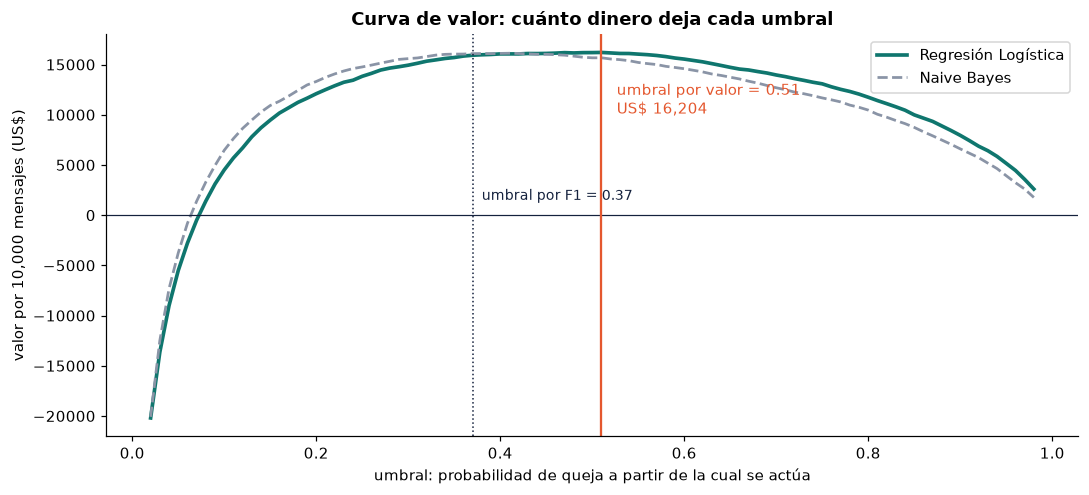

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(curvas.index, curvas["Regresión Logística"], color=TEAL, lw=2.4, label="Regresión Logística")
ax.plot(curvas.index, curvas["Naive Bayes"], color=GRIS, lw=1.8, ls="--", label="Naive Bayes")
ax.axhline(0, color=NAVY, lw=0.8)
ax.axvline(u_opt, color=NARANJA, lw=1.5)
ax.annotate(f"umbral por valor = {u_opt:.2f}\nUS$ {curvas['Regresión Logística'].max():,.0f}",
            (u_opt, curvas["Regresión Logística"].max()), xytext=(10, -40), textcoords="offset points", color=NARANJA)
ax.axvline(u_f1, color=NAVY, lw=1, ls=":")
ax.annotate(f"umbral por F1 = {u_f1:.2f}", (u_f1, 0), xytext=(6, 10), textcoords="offset points", color=NAVY, fontsize=9)
ax.set_xlabel("umbral: probabilidad de queja a partir de la cual se actúa")
ax.set_ylabel("valor por 10,000 mensajes (US$)")
ax.set_title("Curva de valor: cuánto dinero deja cada umbral")
ax.legend()
guardar("11_curva_de_valor")

**Lectura:**
- **Contactar a todos pierde US$ 82,855 por cada 10,000 mensajes** (se gastan cupones en clientes contentos) y **la regla de sentido común deja solo US$ 4,673**. La Regresión Logística con el umbral elegido por valor deja **US$ 16,204**: 3.5 veces más que la regla.
- **El umbral se eligió por valor, no por F1.** El umbral que maximiza el F1 es 0.37 y el que maximiza el dinero es 0.51. Con 0.37 el modelo detecta más quejas (recall 84 %), pero cada falso positivo cuesta US$ 13.43 y eso no compensa: el umbral por valor deja US$ 278 más por cada 10,000 mensajes que el umbral por F1, y US$ 582 más que usar la clase más probable.
- **Naive Bayes y Regresión Logística casi empatan en dinero** en su mejor umbral (US$ 16,126 contra US$ 16,204). La Regresión Logística se queda porque su curva es **más estable alrededor del óptimo**: entre los umbrales 0.4 y 0.6 baja de US$ 16,058 a US$ 15,542, mientras que Naive Bayes cae a US$ 14,582. Si el umbral se mueve porque cambia un supuesto, la Regresión Logística pierde menos dinero. Además es mejor en las tres clases (F1 macro 0.69 contra 0.63).
- **A escala:** una tienda con 10,000 mensajes al mes recuperaría unos **US$ 194,000 al año** con el umbral por valor.

### 6.1 Análisis de sensibilidad (±20 % y ±50 %)
Cambiamos cada supuesto, uno a la vez, y volvemos a buscar el mejor umbral.

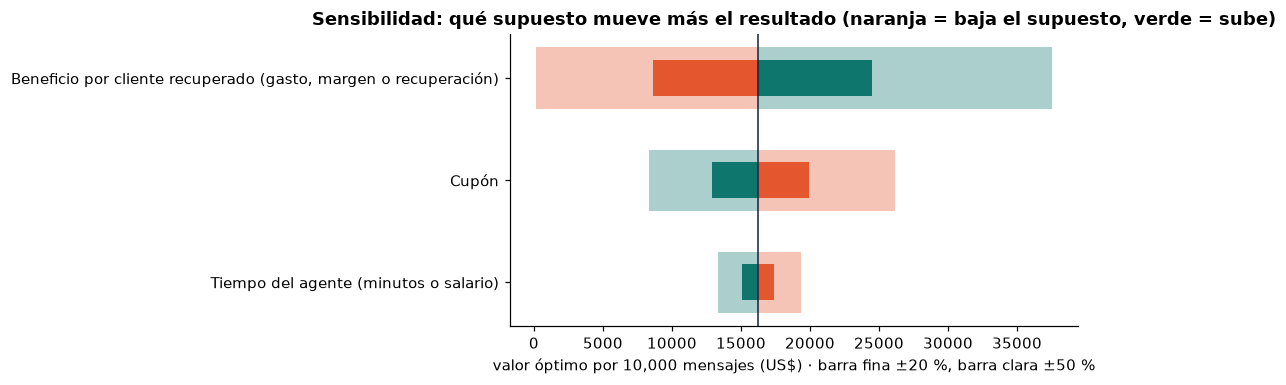

,supuesto,cambio,umbral óptimo,valor óptimo (US$),valor con el umbral base (US$)
0,"Beneficio por cliente recuperado (gasto, margen o recuperación)",-50%,0.96,124.47,-3018.11
1,"Beneficio por cliente recuperado (gasto, margen o recuperación)",-20%,0.57,8653.18,8515.40
2,"Beneficio por cliente recuperado (gasto, margen o recuperación)",+20%,0.37,24526.03,23893.41
3,"Beneficio por cliente recuperado (gasto, margen o recuperación)",+50%,0.32,37545.45,35426.92
4,Cupón,-50%,0.28,26163.46,24483.58
5,Cupón,-20%,0.37,19957.43,19516.07
6,Cupón,+20%,0.54,12920.74,12892.73
7,Cupón,+50%,0.60,8361.96,7925.23
8,Tiempo del agente (minutos o salario),-50%,0.37,19384.69,19045.54
9,Tiempo del agente (minutos o salario),-20%,0.47,17388.87,17340.86


In [30]:
# gasto × margen × recuperación se multiplican, así que mover cualquiera de los tres tiene el mismo efecto
# (igual con minutos × salario): los agrupamos para no repetir filas idénticas
GRUPOS = {"Beneficio por cliente recuperado (gasto, margen o recuperación)": "gasto_anual",
          "Cupón": "cupon", "Tiempo del agente (minutos o salario)": "minutos_agente"}
filas = []
for nombre, clave in GRUPOS.items():
    for factor in [0.5, 0.8, 1.2, 1.5]:
        s = dict(SUPUESTOS, **{clave: SUPUESTOS[clave] * factor})
        curva_s = pd.Series([valor(p_lr >= u, s) for u in UMBRALES], index=UMBRALES)
        filas.append({"supuesto": nombre, "cambio": f"{factor - 1:+.0%}",
                      "umbral óptimo": curva_s.idxmax(), "valor óptimo (US$)": curva_s.max(),
                      "valor con el umbral base (US$)": valor(p_lr >= u_opt, s)})
sensibilidad = pd.DataFrame(filas)
valor_base = curvas["Regresión Logística"].max()

pivote = sensibilidad.pivot(index="supuesto", columns="cambio", values="valor óptimo (US$)")[["-50%", "-20%", "+20%", "+50%"]]
orden = (pivote.max(axis=1) - pivote.min(axis=1)).sort_values().index
fig, ax = plt.subplots(figsize=(10, 3.6))
for i, sup in enumerate(orden):
    fila = pivote.loc[sup]
    ax.barh(i, fila["-50%"] - valor_base, left=valor_base, color=NARANJA, alpha=0.35, height=0.6)
    ax.barh(i, fila["+50%"] - valor_base, left=valor_base, color=TEAL, alpha=0.35, height=0.6)
    ax.barh(i, fila["-20%"] - valor_base, left=valor_base, color=NARANJA, height=0.35)
    ax.barh(i, fila["+20%"] - valor_base, left=valor_base, color=TEAL, height=0.35)
ax.axvline(valor_base, color=NAVY, lw=1)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlabel("valor óptimo por 10,000 mensajes (US$) · barra fina ±20 %, barra clara ±50 %")
ax.set_title("Sensibilidad: qué supuesto mueve más el resultado (naranja = baja el supuesto, verde = sube)")
guardar("12_sensibilidad")
sensibilidad.round(2)

**Lectura de la sensibilidad:**
- **El supuesto que más pesa es el beneficio por cliente recuperado** (gasto anual × margen × tasa de recuperación). Con ±20 % el valor va de US$ 8,653 a US$ 24,526 por cada 10,000 mensajes: sigue siendo positivo.
- **Con −50 % en el beneficio**, una queja recuperada vale US$ 14.25 y la acción cuesta US$ 13.43: casi no queda margen. El umbral óptimo sube a 0.96 (actuar solo cuando el modelo está casi seguro) y el valor queda en US$ 124. **Si se mantuviera el umbral de 0.51, el sistema perdería US$ 3,018.** Esto muestra por qué el umbral se elige por valor y se recalcula cuando cambian los supuestos.
- El cupón y el tiempo del agente mueven menos el resultado: con ±50 % el valor sigue entre US$ 8,362 y US$ 26,163.
- En producción, **el umbral es un parámetro de negocio**: se recalcula cuando cambian el cupón, el margen o el salario, sin reentrenar el modelo.

---
## 7. Limitaciones

- **Las estrellas son una aproximación a la satisfacción.** Solo una parte de los clientes escribe reseñas, y quienes lo hacen tienden a estar muy contentos o muy molestos.
- **El volumen es una estimación:** total oficial de la categoría × proporción de reseñas desde 2019, medida en unas 10,000 reseñas por categoría (error de ±1 punto en la proporción).
- **Muestra de 20,000 reseñas por categoría:** el % negativo tiene un margen de error de ±0.5 puntos. Los trozos aleatorios traen varias reseñas seguidas del mismo cliente; por eso se usaron 1,000 trozos por categoría (hay 239,139 usuarios distintos en 300,000 reseñas).
- **Los temas se detectan con un diccionario de palabras clave.** Es transparente, pero cubre el 63.5 % de las reseñas negativas y puede fallar con sarcasmo o con palabras de doble sentido ("fit").
- **La clase neutra es difícil de clasificar** (F1 = 0.36). Para el uso de negocio (detectar quejas) importa más la clase negativa (F1 = 0.78).
- **Mercado y periodo:** son datos de Amazon Estados Unidos, en inglés, hasta septiembre de 2023. El método se aplica igual a reseñas de una tienda guatemalteca en español; solo cambian las stopwords y el diccionario de temas.
- **El clasificador del dashboard solo entiende inglés**, porque se entrenó con estos datos.
- **TF-IDF con bigramas no entiende negaciones largas.** Capta "not bad" o "not disappointed", pero en "I was worried after reading some reviews, but I was not disappointed at all" pesan más "worried" y "not" y la clasifica como negativa. Un modelo que lee la oración completa (como BERT, visto al final del curso) resolvería mejor estos casos.

---
## 8. Exportación al dashboard
El dashboard es una página web estática: lee `dashboard/datos.json` (ranking, temas, frases, tendencia y ejemplos) y `dashboard/modelo.json` (vocabulario, IDF y pesos de la regresión logística) para clasificar texto nuevo directamente en el navegador, con la misma limpieza de este notebook.

In [31]:
DASH = Path("dashboard")
DASH.mkdir(exist_ok=True)

modelo_json = {
    "clases": list(mejor_lr.classes_),
    "intercepto": mejor_lr.intercept_.round(4).tolist(),
    "stopwords": STOPWORDS,
    "vocab": {t: [round(float(tfidf.idf_[i]), 4)] + mejor_lr.coef_[:, i].round(4).tolist()
              for t, i in tfidf.vocabulary_.items()},
}
(DASH / "modelo.json").write_text(json.dumps(modelo_json, separators=(",", ":")))

# verificación: las probabilidades del modelo exportado deben coincidir con las de scikit-learn
def predecir_exportado(texto):
    tokens = [w for w in re.findall(r"(?u)\b\w\w+\b", limpiar(texto)) if w not in set(STOPWORDS)]
    terminos_txt = tokens + [f"{a} {b}" for a, b in zip(tokens, tokens[1:])]
    conteo = pd.Series(terminos_txt).value_counts()
    conteo = conteo[conteo.index.isin(modelo_json["vocab"].keys())]
    if conteo.empty:
        return None
    v = np.array([(1 + np.log(c)) * modelo_json["vocab"][t][0] for t, c in conteo.items()])
    v = v / np.linalg.norm(v)
    W = np.array([modelo_json["vocab"][t][1:] for t in conteo.index])
    z = v @ W + np.array(modelo_json["intercepto"])
    return np.exp(z) / np.exp(z).sum()

prueba_txt = X_test.iloc[:200]
dif = max(np.abs(predecir_exportado(t) - mejor_lr.predict_proba(tfidf.transform([limpiar(t)]))[0]).max()
          for t in df.loc[prueba_txt.index, "texto_completo"] if predecir_exportado(t) is not None)
print(f"Diferencia máxima entre modelo exportado y scikit-learn: {dif:.6f}")
print(f"modelo.json: {(DASH / 'modelo.json').stat().st_size / 1e6:.1f} MB")

Diferencia máxima entre modelo exportado y scikit-learn: 0.000039
modelo.json: 2.2 MB


In [32]:
# Resultados por categoría para el dashboard (los textos en inglés se traducen en 04_construir_dashboard.py)
ID_DE = {v: k for k, v in CATEGORIA_ES.items()}
anios = df["fecha"].dt.year
ultimo = trimestral.index[-4:]  # últimos 4 trimestres completos
categorias_json = []
for cat, fila in prioridad.iterrows():
    serie = trimestral[cat].rolling(2, min_periods=1).mean()
    base_2019 = trimestral.loc[trimestral.index.year == 2019, cat].mean()
    ej = evidencia(cat)
    categorias_json.append({
        "id": ID_DE[cat], "nombre": cat,
        "pct_neg": round(fila["pct_negativa"], 2), "margen": round(fila["margen_error"], 2),
        "volumen_m": round(fila["resenas_2019_millones"], 3),
        "negativas_m": round(fila["negativas_estimadas_millones"], 3),
        "cambio_pp": round(trimestral.loc[ultimo, cat].mean() - base_2019, 2),
        "temas": temas_cat.loc[cat].round(1).to_dict(),
        "causa": causa_principal[cat],
        "frases": frases_cat[cat][:6],
        "tendencia": [{"t": str(t), "v": round(v, 2)} for t, v in serie.items()],
        "anios": [{"anio": int(a), "pct": round(pct_anio.loc[cat, a], 2), "negativas_m": round(neg_anio.loc[cat, a], 3)}
                  for a in pct_anio.columns],
        "ejemplos": [{"clave": f"{r['user_id']}-{r['timestamp']}", "estrellas": int(r["rating"]),
                      "votos": int(r["helpful_vote"]), "titulo": r["title"], "texto": r["text"]}
                     for _, r in ej.iterrows()],
    })

lr_test = tabla_test.set_index("modelo").loc["Regresión Logística"]
datos_json = {
    "meta": {"resenas": len(df), "categorias": df["category"].nunique(),
             "periodo": f"{df['fecha'].min():%Y} - {df['fecha'].max():%Y}",
             "accuracy": round(lr_test["accuracy"], 3), "f1_macro": round(lr_test["F1 macro"], 3)},
    "categorias": categorias_json,
    "anios": [int(a) for a in pct_anio.columns],
    "valor": {
        "supuestos": SUPUESTOS, "beneficio": round(b, 2), "costo": round(c, 2),
        "umbral_valor": float(u_opt), "umbral_f1": float(u_f1),
        "curva": [{"u": float(u), "lr": round(v, 1), "nb": round(curvas.loc[u, "Naive Bayes"], 1)} for u, v in curvas["Regresión Logística"].items()],
        "estrategias": estrategias.round(3).to_dict(orient="records"),
        "sensibilidad": sensibilidad.round(2).to_dict(orient="records"),
        # verdaderos y falsos positivos por umbral: con esto el dashboard recalcula el valor con cualquier supuesto
        "n_prueba": int(len(es_queja)),
        "n_quejas": int(es_queja.sum()),
        "conteos": [{"u": float(u), "vp": int(((p_lr >= u) & es_queja).sum()), "fp": int(((p_lr >= u) & ~es_queja).sum())}
                    for u in UMBRALES],
    },
    "experimentos": {
        "comparacion": comparacion.round(3).to_dict(orient="records"),
        "curva": curva.round(3).to_dict(orient="records"),
        "sin_estrellas": {
            col: {"top3": [ID_DE[c] for c in negativas_sin_estrellas[col].sort_values(ascending=False).index[:3]],
                  "total_m": round(negativas_sin_estrellas[col].sum(), 2)}
            for col in negativas_sin_estrellas.columns},
    },
}
(DASH / "datos.json").write_text(json.dumps(datos_json, ensure_ascii=False, indent=1))
print(f"datos.json: {len(categorias_json)} categorías")

datos.json: 15 categorías


---
## 9. Viabilidad: costo, latencia y mantenimiento medidos
Medimos en esta computadora (laptop, sin GPU) lo que costaría operar SAR.

In [33]:
import time

t0 = time.perf_counter()
LogisticRegression(C=mejor_lr.C, class_weight="balanced", max_iter=2000, random_state=SEMILLA).fit(Xtr, y_train)
segundos_entrenamiento = time.perf_counter() - t0

muestra_txt = df.loc[X_test.index[:2000], "texto_completo"].tolist()
t0 = time.perf_counter()
for texto in muestra_txt:
    mejor_lr.predict_proba(tfidf.transform([limpiar(texto)]))
ms_por_mensaje = (time.perf_counter() - t0) / len(muestra_txt) * 1000

t0 = time.perf_counter()
mejor_lr.predict_proba(tfidf.transform([limpiar(t) for t in muestra_txt]))
por_segundo_lote = len(muestra_txt) / (time.perf_counter() - t0)

viabilidad = {
    "entrenamiento_segundos": round(segundos_entrenamiento, 1),
    "latencia_ms_por_mensaje": round(ms_por_mensaje, 2),
    "mensajes_por_segundo_en_lote": int(por_segundo_lote),
    "tamano_modelo_mb": round((DASH / "modelo.json").stat().st_size / 1e6, 1),
    "terminos_vocabulario": len(tfidf.vocabulary_),
}
(DASH / "viabilidad.json").write_text(json.dumps(viabilidad, indent=1))
viabilidad

{'entrenamiento_segundos': 5.1,
 'latencia_ms_por_mensaje': 0.16,
 'mensajes_por_segundo_en_lote': 53876,
 'tamano_modelo_mb': 2.2,
 'terminos_vocabulario': 50000}

**Lectura:**
- **Entrenar** el modelo con 206,807 reseñas toma segundos en una laptop, así que reentrenarlo cada mes no cuesta nada en cómputo.
- **Clasificar** un mensaje toma milisegundos y en lote se procesan miles por segundo: la latencia no es un problema ni para atención en tiempo real.
- **El modelo pesa unos 2 MB** y en el dashboard corre dentro del navegador del usuario: no hace falta servidor de inferencia (el dashboard está publicado gratis en Render como sitio estático) y **los textos de los clientes no salen de la computadora** de quien usa el dashboard.